# Lab 4: Data is Delicious

**Nicolas Ramel — September 27, 2026**

Popular ebooks: a webpage scrape and an API join

I selected **Option B for Part 1 and Option B for Part 2**. I use Project Gutenberg's popular ebooks list to build a small reading shortlist, then add book metadata from Gutendex. My question is: **What are the first 10 books in the daily ranking, and what authors, languages, and ebook formats are associated with them?**

## Part 1 — Option B: Scrape a webpage

### Data, purpose, and source

The source is Project Gutenberg's [Frequently Viewed or Downloaded page](https://www.gutenberg.org/browse/scores/top#books-last1). I scrape the first 10 entries under **Top 100 EBooks yesterday**, rather than mixing that list with the weekly, monthly, or author rankings elsewhere on the page. A manageable shortlist lets me inspect every joined record.

The observational unit is **one ebook catalog entry in that daily ranking**. Different editions of the same work may have separate IDs. The main variables are the rank, Gutenberg book ID, displayed title/author label, daily download count, book URL, and the date reported by the page. The list is ordinary HTML links inside an ordered list. I parse it with **BeautifulSoup**, without using `pd.read_html`.

### Request and preserve the source

I save the raw responses so rerunning the analysis does not repeatedly contact the websites. The function below makes an actual HTTP request when a saved file is absent, checks the response, and records its URL, retrieval time, and SHA-256 checksum. When a saved response exists, the same code reads and verifies it. The submitted data files preserve the responses used for these results.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin
import hashlib
import json
import re
import time
from textwrap import shorten

import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from IPython.display import display, Markdown

RAW = Path("Data/lab4/raw")
RESULTS = Path("Data/lab4/results")
RAW.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.max_columns", 12)

session = requests.Session()
session.headers.update({"User-Agent": "GSB5544-Lab4 (educational data analysis)"})

def get_saved_response(url, filename):
    path = RAW / filename
    metadata_path = path.with_suffix(".metadata.json")
    requested_url = requests.Request("GET", url).prepare().url
    if path.exists():
        content = path.read_bytes()
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        assert metadata["url"] == requested_url, "Saved response is for another URL."
        assert metadata["sha256"] == hashlib.sha256(content).hexdigest()
    else:
        response = session.get(requested_url, timeout=(10, 30))
        response.raise_for_status()
        content = response.content
        metadata = {
            "file": filename,
            "url": response.url,
            "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
            "status_code": response.status_code,
            "sha256": hashlib.sha256(content).hexdigest(),
        }
        path.write_bytes(content)
        metadata_path.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
        time.sleep(0.25)
    return content, metadata

SOURCE_URL = "https://www.gutenberg.org/browse/scores/top"
html, website_metadata = get_saved_response(SOURCE_URL, "gutenberg_top.html")
soup = BeautifulSoup(html, "html.parser")

### Parse and clean the HTML

The page includes several rankings, so I select the heading with ID `books-last1` and its next ordered list. The book ID comes from the link, not from the number in parentheses. The final parentheses contain the download count. I keep the title/author label together because some labels have no author and some titles contain punctuation or the word “by.” The API will provide separate title and author fields in Part 2.

In [2]:
heading = soup.find("h2", id="books-last1")
if heading is None:
    raise ValueError("Could not find the daily ebook ranking.")
items = heading.find_next("ol").find_all("li", recursive=False)

date_cell = soup.select_one("#books-downloads-table tr th")
if date_cell is None:
    raise ValueError("Could not find the source reporting date.")
ranking_date = pd.to_datetime(date_cell.get_text(strip=True), format="%Y-%m-%d")

N_BOOKS = 10
assert len(items) >= N_BOOKS
rows = []
for rank, item in enumerate(items[:N_BOOKS], start=1):
    link = item.find("a", href=re.compile(r"^/ebooks/\d+$"))
    if link is None:
        raise ValueError(f"Missing ebook link at rank {rank}.")
    label = link.get_text(" ", strip=True)
    match = re.fullmatch(r"(.+)\s+\(([\d,]+)\)", label)
    if match is None:
        raise ValueError(f"Unexpected ranking label: {label}")
    rows.append({
        "rank": rank,
        "book_id": int(link["href"].rsplit("/", 1)[-1]),
        "listing_label": match.group(1).strip(),
        "daily_downloads": int(match.group(2).replace(",", "")),
        "book_url": urljoin(SOURCE_URL, link["href"]),
        "ranking_date": ranking_date,
    })

web_books = pd.DataFrame(rows)
assert len(web_books) == N_BOOKS
assert web_books["book_id"].is_unique
assert web_books.notna().all().all()
assert web_books["daily_downloads"].ge(0).all()
assert web_books["daily_downloads"].is_monotonic_decreasing
assert web_books["rank"].tolist() == list(range(1, N_BOOKS + 1))
display(web_books.head())
print(f"Webpage DataFrame: {web_books.shape[0]} rows, {web_books.shape[1]} columns")
print("Ranking date shown by source:", ranking_date.date())
print("HTML retrieved at (UTC):", website_metadata["retrieved_at_utc"])

,rank,book_id,listing_label,daily_downloads,book_url,ranking_date
0,1,2701,"Moby Dick; Or, The Whale by Herman Melville",7134,https://www.gutenberg.org/ebooks/2701,2026-08-02
1,2,1342,Pride and Prejudice by Jane Austen,7123,https://www.gutenberg.org/ebooks/1342,2026-08-02
2,3,1727,The Odyssey by Homer,5768,https://www.gutenberg.org/ebooks/1727,2026-08-02
3,4,2641,A Room with a View by E. M. Forster,5195,https://www.gutenberg.org/ebooks/2641,2026-08-02
4,5,2554,Crime and Punishment by Fyodor Dostoyevsky,4859,https://www.gutenberg.org/ebooks/2554,2026-08-02


Webpage DataFrame: 10 rows, 6 columns
Ranking date shown by source: 2026-08-02
HTML retrieved at (UTC): 2026-09-28T04:00:06.337558+00:00


**Date note:** The saved HTML reports **August 2, 2026**, even though it was retrieved on September 28 UTC (September 27 in California). I use the source's explicit date and treat this as an August 2 snapshot. The page's “yesterday” heading should not be interpreted as the day before submission.

The numeric variables are integers, `ranking_date` is a date, and the label and URL are text. The assertions check that there are 10 distinct IDs, no missing scraped values, nonnegative counts, and ranks in the same order as the source. Project Gutenberg describes these counts as downloads with filtering for repeated addresses and heavy automated activity; they are not a count of people who read or finished a book.

## Part 2 — Option B: Request related API data

### Data, purpose, and source

I use the [Gutendex API](https://gutendex.com/), which provides metadata for Project Gutenberg ebooks. The individual-book endpoint is `https://gutendex.com/books/<id>/`; [book 1342](https://gutendex.com/books/1342/) is one example. This is a separate JSON API request, not another parse of the ranking webpage. No API key is needed for these requests.

The observational unit is **one API book record with a Gutenberg ID**. I request the same 10 IDs from Part 1, so the metadata directly describes the ranked entries. The variables are `book_id`, `api_title`, `authors`, `languages` (language codes), `media_type`, and `has_epub` (whether the returned formats include EPUB). These add cleaner titles, author names, language information, and a useful reading format indicator to the shortlist.

### Request JSON and make a second DataFrame

I use the individual-book endpoint because the filtered list endpoint timed out during collection. There are 10 successful book responses, each saved once for reuse. An individual response represents one book, so there is no pagination to follow. Authors and languages are arrays in the JSON. I combine each array into a semicolon-separated string to keep one row per book; an empty array becomes a missing value.

In [3]:
def join_values(values):
    return "; ".join(values) if values else pd.NA

api_rows = []
api_metadata = []
for book_id in web_books["book_id"]:
    api_url = f"https://gutendex.com/books/{book_id}/"
    content, metadata = get_saved_response(api_url, f"gutendex_{book_id}.json")
    book = json.loads(content)
    assert book["id"] == book_id, "API response has an unexpected book ID."
    api_metadata.append(metadata)
    api_rows.append({
        "book_id": book["id"],
        "api_title": book["title"],
        "authors": join_values([author["name"] for author in book["authors"]]),
        "languages": join_values(book["languages"]),
        "media_type": book["media_type"],
        "has_epub": "application/epub+zip" in book["formats"],
    })

api_books = pd.DataFrame(api_rows)
api_books["has_epub"] = api_books["has_epub"].astype("boolean")
assert api_books["book_id"].is_unique
assert api_books["api_title"].notna().all()
assert set(api_books["book_id"]) == set(web_books["book_id"])
display(api_books.head())
print(f"API DataFrame: {api_books.shape[0]} rows, {api_books.shape[1]} columns")

,book_id,api_title,authors,languages,media_type,has_epub
0,2701,"Moby Dick; Or, The Whale","Melville, Herman",en,Text,True
1,1342,Pride and Prejudice,"Austen, Jane",en,Text,True
2,1727,The Odyssey: Rendered into English prose for the use of those who cannot read the...,Homer,en,Text,True
3,2641,A Room with a View,"Forster, E. M. (Edward Morgan)",en,Text,True
4,2554,Crime and Punishment,"Dostoyevsky, Fyodor",en,Text,True


API DataFrame: 10 rows, 6 columns


### Join the two sources

Both sources use the same Gutenberg book ID, so I use an exact match. Fuzzy matching is unnecessary and could confuse separate editions or similar titles. A left join retains every scraped book, and `validate="one_to_one"` rejects duplicate keys. The merge indicator makes unmatched books visible.

In [4]:
books = web_books.merge(
    api_books, on="book_id", how="left", validate="one_to_one", indicator=True
).sort_values("rank").reset_index(drop=True)

match_counts = books["_merge"].value_counts().reindex(
    ["both", "left_only", "right_only"], fill_value=0
)
display(match_counts.rename_axis("join_status").to_frame("rows"))
unmatched = books.loc[books["_merge"] != "both", ["rank", "book_id", "listing_label"]]
print("Unmatched scraped books:", len(unmatched))
if not unmatched.empty:
    display(unmatched)

assert len(books) == len(web_books)
assert books["book_id"].is_unique
assert books["_merge"].eq("both").all()
books = books.drop(columns="_merge")
display(books[["rank", "book_id", "api_title", "authors", "languages", "daily_downloads"]].head())

,rows
join_status,
both,10
left_only,0
right_only,0


Unmatched scraped books: 0


,rank,book_id,api_title,authors,languages,daily_downloads
0,1,2701,"Moby Dick; Or, The Whale","Melville, Herman",en,7134
1,2,1342,Pride and Prejudice,"Austen, Jane",en,7123
2,3,1727,The Odyssey: Rendered into English prose for the use of those who cannot read the...,Homer,en,5768
3,4,2641,A Room with a View,"Forster, E. M. (Edward Morgan)",en,5195
4,5,2554,Crime and Punishment,"Dostoyevsky, Fyodor",en,4859


The join retains **10 books, with 10 matches and no unmatched IDs**. The separate source labels remain in `listing_label`, while `api_title` and `authors` come from the API. Matching on the identifier avoids problems with abbreviated author names or slightly different title formatting.

### Results from the joined data

In [5]:
language_summary = (
    books.groupby("languages", dropna=False)
    .agg(books=("book_id", "size"), daily_downloads=("daily_downloads", "sum"))
    .sort_values("books", ascending=False)
    .reset_index()
)
display(language_summary)

leader = books.iloc[0]
epub_count = int(books["has_epub"].sum())
missing_authors = int(books["authors"].isna().sum())
display(Markdown(
    f"The highest-ranked entry in this snapshot is **{leader['api_title']}**, "
    f"with **{leader['daily_downloads']:,} daily downloads**. "
    f"The 10 listed entries account for **{books['daily_downloads'].sum():,} downloads** "
    f"on the source's reporting date. The API lists an EPUB format for "
    f"**{epub_count} of the {len(books)} books**; "
    f"**{missing_authors}** entries have missing author metadata."
))

,languages,books,daily_downloads
0,en,10,53207


The highest-ranked entry in this snapshot is **Moby Dick; Or, The Whale**, with **7,134 daily downloads**. The 10 listed entries account for **53,207 downloads** on the source's reporting date. The API lists an EPUB format for **10 of the 10 books**; **0** entries have missing author metadata.

The language table groups the complete language-code string for each book; a book with multiple languages would remain one observation. The download total covers only this selected shortlist, not the whole Gutenberg catalog.

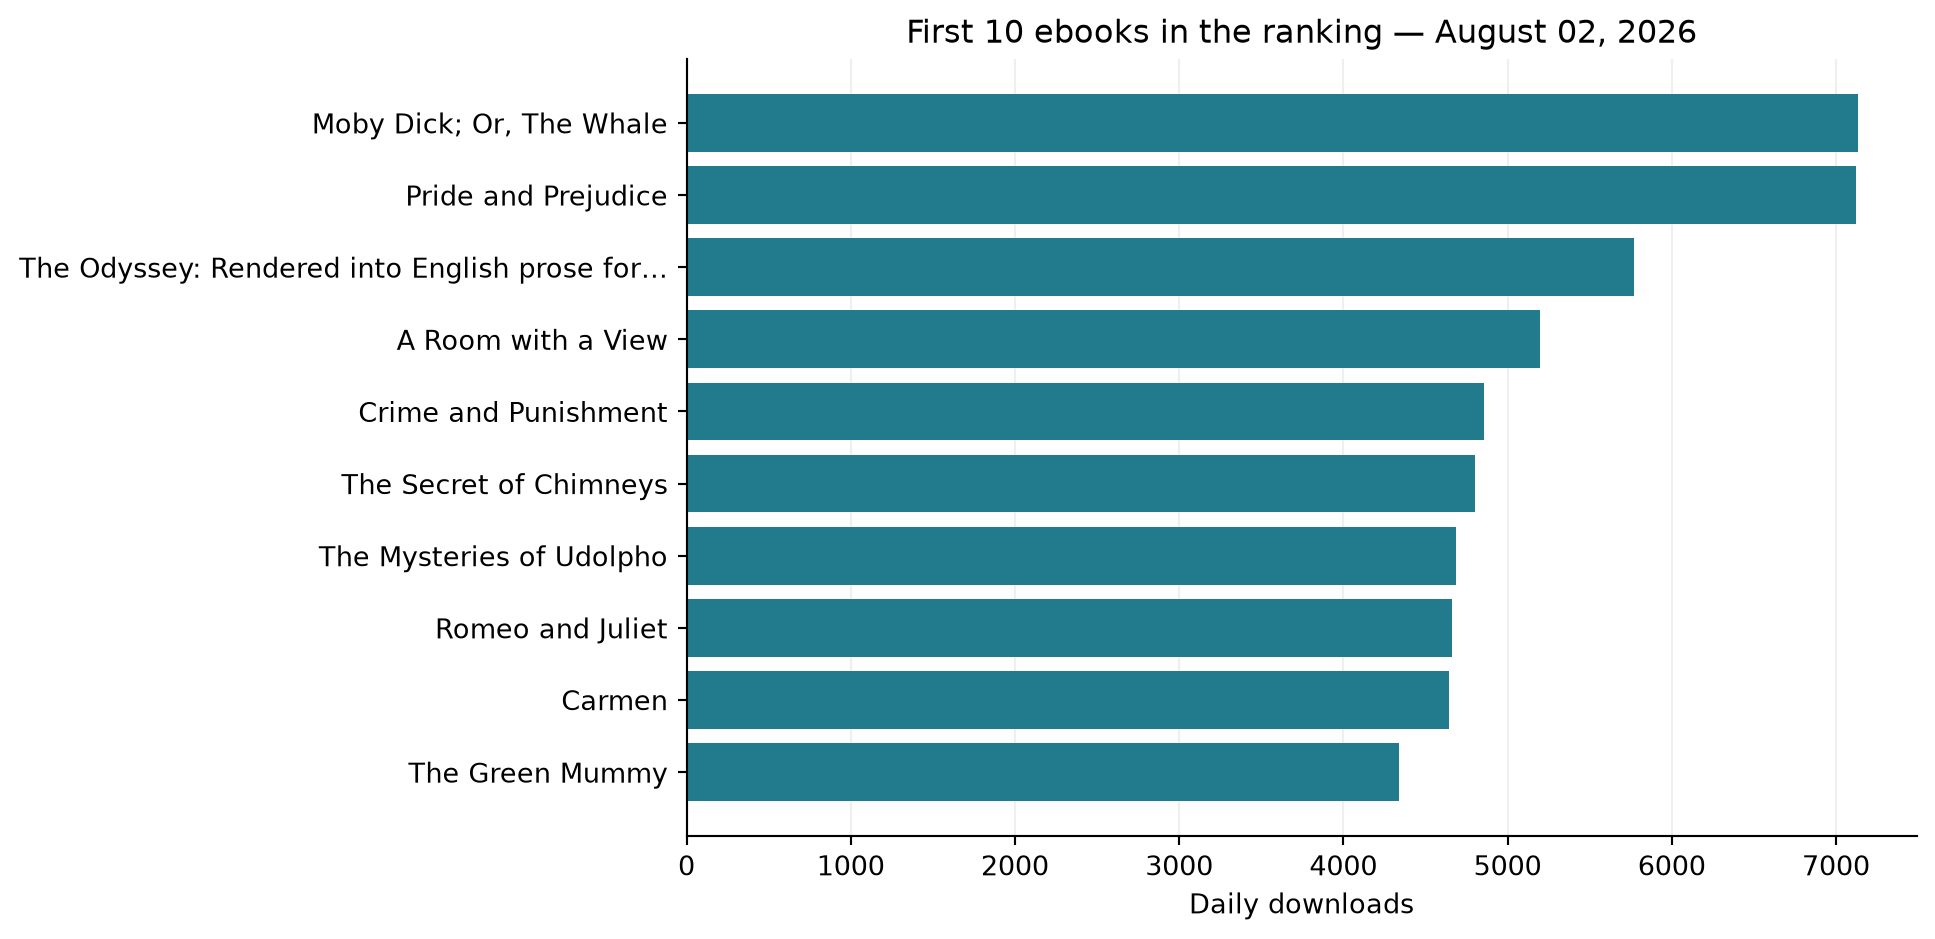

In [6]:
#| fig-cap: Daily downloads for the first 10 ranked ebooks in the saved August 2, 2026 snapshot. Titles come from the API; counts come from the webpage. Long titles are shortened here and retained in full in the table below.
top10 = books.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
plot_labels = [shorten(title, width=47, placeholder="…") for title in top10["api_title"]]
ax.barh(plot_labels, top10["daily_downloads"], color="#227b8d")
ax.set_xlabel("Daily downloads")
ax.set_ylabel("")
ax.set_title(f"First 10 ebooks in the ranking — {ranking_date:%B %d, %Y}")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

The API adds practical information that the ranking page alone does not separate cleanly. For example, I can now select books by language and check whether an EPUB version is available while retaining their original ranks and counts.

There are limits to this comparison. These are the first 10 entries of one ranking, not a random sample of all books or readers. The ranking snapshot and API metadata were not necessarily updated at the same time. I keep the webpage's daily downloads and do not substitute the API's `download_count`, since its reporting period is not specified in the API documentation. An available file format also says nothing about how many readers used that format.

### Complete joined shortlist

The table below shows every selected observation. The exported joined CSV also includes the original source labels, URLs, reporting date, and media type.

In [7]:
display(books[[
    "rank", "book_id", "api_title", "authors", "languages", "daily_downloads", "has_epub"
]].style.hide(axis="index"))

rank,book_id,api_title,authors,languages,daily_downloads,has_epub
1,2701,"Moby Dick; Or, The Whale","Melville, Herman",en,7134,True
2,1342,Pride and Prejudice,"Austen, Jane",en,7123,True
3,1727,The Odyssey: Rendered into English prose for the use of those who cannot read the original,Homer,en,5768,True
4,2641,A Room with a View,"Forster, E. M. (Edward Morgan)",en,5195,True
5,2554,Crime and Punishment,"Dostoyevsky, Fyodor",en,4859,True
6,65238,The Secret of Chimneys,"Christie, Agatha",en,4800,True
7,3268,The Mysteries of Udolpho,"Radcliffe, Ann Ward",en,4688,True
8,1513,Romeo and Juliet,"Shakespeare, William",en,4660,True
9,2465,Carmen,"Mérimée, Prosper",en,4643,True
10,2868,The Green Mummy,"Hume, Fergus",en,4337,True


### Export and verify

In [8]:
web_books.to_csv(RESULTS / "part1_web_books.csv", index=False, date_format="%Y-%m-%d")
api_books.to_csv(RESULTS / "part2_api_books.csv", index=False)
books.to_csv(RESULTS / "joined_books.csv", index=False, date_format="%Y-%m-%d")
language_summary.to_csv(RESULTS / "language_summary.csv", index=False)

source_log = [website_metadata] + api_metadata
(RAW.parent / "source_metadata.json").write_text(
    json.dumps(source_log, indent=2) + "\n", encoding="utf-8"
)

saved_books = pd.read_csv(RESULTS / "joined_books.csv", parse_dates=["ranking_date"])
assert saved_books["book_id"].tolist() == books["book_id"].tolist()
assert saved_books["daily_downloads"].sum() == books["daily_downloads"].sum()
assert saved_books["api_title"].tolist() == books["api_title"].tolist()
assert all(record["status_code"] == 200 for record in source_log)
print("Verified: 10 scraped books, 10 API records, 10 unique joined rows.")
print("All source checksums passed; the exported IDs, titles, and download total agree.")
print("CSV files saved in", RESULTS)

Verified: 10 scraped books, 10 API records, 10 unique joined rows.
All source checksums passed; the exported IDs, titles, and download total agree.
CSV files saved in Data/lab4/results


The saved HTML and JSON files allow the same code to recreate the DataFrames, join, summaries, and figure without further network requests. Source URLs and retrieval timestamps are included in `Data/lab4/source_metadata.json`.